In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

print("Rows and columns:", df.shape)
display(df.head())
display(df.tail())

Rows and columns: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [2]:
df.info()
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 107


In [3]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
display(missing.sort_values("missing_count", ascending=False))

,missing_count,missing_percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


In [4]:
clean = df.copy()

# Fill numeric age values with the median
clean["age"] = clean["age"].fillna(clean["age"].median())

# Fill categorical values with the most common value
for col in ["embarked", "embark_town"]:
    clean[col] = clean[col].fillna(clean[col].mode()[0])

# Many deck values are missing; drop this column and explain why
clean = clean.drop(columns=["deck"])

# Remove exact duplicate rows
clean = clean.drop_duplicates()

print("Shape after cleaning:", clean.shape)
print("Missing values remaining:", clean.isna().sum().sum())
print("Duplicate rows remaining:", clean.duplicated().sum())

Shape after cleaning: (775, 14)
Missing values remaining: 0
Duplicate rows remaining: 0


,age,fare
count,775.000000,775.000000
mean,29.581187,34.878403
std,13.766359,52.408474
min,0.420000,0.000000
25%,21.000000,8.050000
50%,28.000000,15.900000
75%,36.000000,34.197900
max,80.000000,512.329200


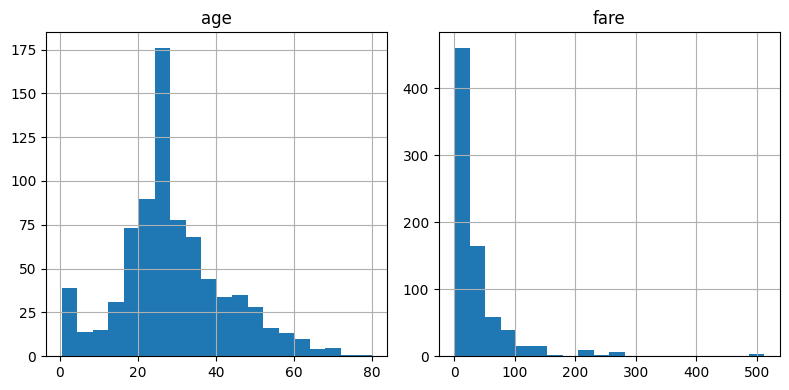

,count
class,
Third,401
First,210
Second,164


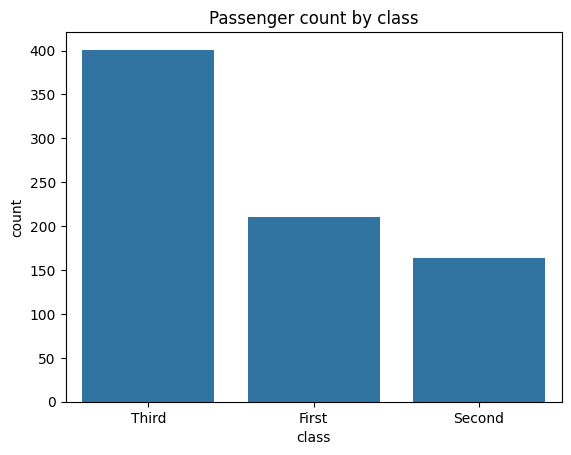

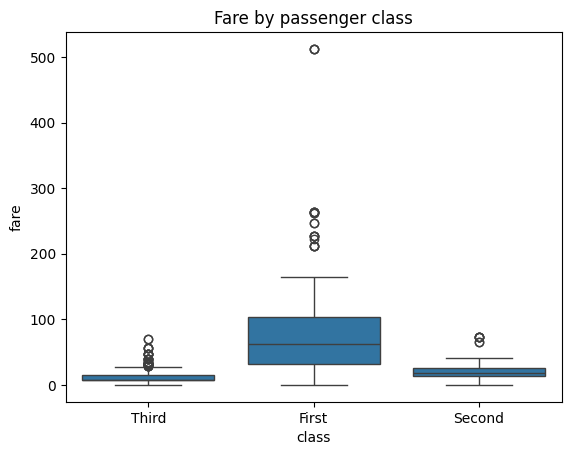

In [5]:
# Numeric summary
display(clean[["age", "fare"]].describe())

# Numeric distributions
clean[["age", "fare"]].hist(figsize=(8, 4), bins=20)
plt.tight_layout()
plt.show()

# Categorical counts
display(clean["class"].value_counts())
sns.countplot(data=clean, x="class")
plt.title("Passenger count by class")
plt.show()

# Compare two columns
sns.boxplot(data=clean, x="class", y="fare")
plt.title("Fare by passenger class")
plt.show()

In [6]:
prepared = clean.copy()

# One-hot encode categories with no natural order
prepared = pd.get_dummies(
    prepared,
    columns=["sex", "embarked", "class"],
    drop_first=True,
    dtype=int
)

# Standardize age and fare
for col in ["age", "fare"]:
    std = prepared[col].std()
    prepared[col + "_scaled"] = (
        (prepared[col] - prepared[col].mean()) / std if std else 0
    )

display(prepared.head())

,survived,pclass,age,sibsp,parch,fare,who,adult_male,embark_town,alive,alone,sex_male,embarked_Q,embarked_S,class_Second,class_Third,age_scaled,fare_scaled
0,0,3,22.0,1,0,7.2500,man,True,Southampton,no,False,1,0,1,0,1,-0.550704,-0.527174
1,1,1,38.0,1,0,71.2833,woman,False,Cherbourg,yes,False,0,0,0,0,0,0.611550,0.694638
2,1,3,26.0,0,0,7.9250,woman,False,Southampton,yes,True,0,0,1,0,1,-0.260140,-0.514295
3,1,1,35.0,1,0,53.1000,woman,False,Southampton,yes,False,0,0,1,0,0,0.393627,0.347684
4,0,3,35.0,0,0,8.0500,man,True,Southampton,no,True,1,0,1,0,1,0.393627,-0.511910


In [7]:
clean.to_csv("titanic_cleaned.csv", index=False)
prepared.to_csv("titanic_prepared.csv", index=False)